# Cozinhas Solidárias: quantas cozinhas cada organização fornecedora atende?


## 1. Preparando o ambiente


In [42]:
# Instala as bibliotecas (se já estiverem instaladas, o pip só avisa e segue em frente)
%pip install pandas matplotlib openpyxl

Note: you may need to restart the kernel to use updated packages.


In [43]:
import pandas as pd              # tabelas (DataFrames): ler, filtrar, agrupar, juntar
import matplotlib.pyplot as plt  # gráficos

## 2. Carregando os dados



### 2.1 Aba de contratações (as organizações fornecedoras)

In [44]:
# Link da aba "contratações", já no formato de download em CSV
url_contratacoes = "https://docs.google.com/spreadsheets/d/1O_mmcnZ2QCBkA6juq_TzKYFv6KDwHsCU/export?format=csv&gid=1251522308"

# Lê o CSV direto da internet. header=10 → o cabeçalho está na 11ª linha (as 10 de cima são título e notas)
df = pd.read_csv(url_contratacoes, header=10)

df.info()   # raio-x da tabela: nº de linhas, nome e tipo de cada coluna, quantos valores estão preenchidos
df.head(3)  # mostra as 3 primeiras linhas para ver o formato dos dados

<class 'pandas.DataFrame'>
RangeIndex: 280 entries, 0 to 279
Data columns (total 30 columns):
 #   Column                                                         Non-Null Count  Dtype  
---  ------                                                         --------------  -----  
 0   ANO                                                            280 non-null    int64  
 1   RECURSO                                                        280 non-null    str    
 2   MECANISMO                                                      280 non-null    str    
 3   MECANISMO RESUMO 1                                             280 non-null    str    
 4   MECANISMO RESUMO 2                                             280 non-null    str    
 5   UF CONAB                                                       280 non-null    str    
 6   UF ORGANIZAÇÃO                                                 280 non-null    str    
 7   N° DO PROJETO                                                  280 non-nu

,ANO,RECURSO,MECANISMO,MECANISMO RESUMO 1,MECANISMO RESUMO 2,UF CONAB,UF ORGANIZAÇÃO,N° DO PROJETO,REGIÃO,CÓDIGO IBGE,...,NºJuventude,NºPCT,NºAssentado,NºAgroextrativista,Nº Povos Indigena,NºPescador Artesanal,Nº Quilombolas,Produto Organico(Kg),TIPO ORGANIZAÇÃO,PRODUTOS PREVISTOS NOS PROJETOS
0,2025,MDS,CDAF/COZINHAS,COZINHAS,CDAF,CE,CE,CE/2025/01/0351,NORDESTE,2309607,...,1,0,0,0,0,0,0,0,COOPERATIVA,HORTIGRANGEIROS
1,2025,MDS,CDAF/COZINHAS,COZINHAS,CDAF,CE,CE,CE/2025/01/0352,NORDESTE,2301000,...,0,5,0,0,0,5,0,0,ASSOCIAÇÃO,PESCADO
2,2025,MDS,CDAF/COZINHAS,COZINHAS,CDAF,CE,CE,CE/2025/01/0353,NORDESTE,2303501,...,0,0,5,0,0,0,0,0,COOPERATIVA,HORTIGRANGEIROS


**O que dá para ver aqui:** são 280 linhas e 30 colunas, e cada linha é **um projeto**. Uma mesma organização pode ter mais de um projeto (como vamos ver mais à frente, são 240 organizações para 280 projetos), então contar linhas não é a mesma coisa que contar organizações.

Para a nossa pergunta, as colunas que importam são `N° DO PROJETO`, `CNPJ`, `ORGANIZAÇÃO FORNECEDORA` e as duas de UF.

### 2.2 Aba de unidades recebedoras (as cozinhas)

In [45]:
# Link da aba "unidades recebedoras" (mesma planilha, outro gid)
url_unidades = "https://docs.google.com/spreadsheets/d/1O_mmcnZ2QCBkA6juq_TzKYFv6KDwHsCU/export?format=csv&gid=225140418"

# Aqui o cabeçalho está na 7ª linha, por isso header=6
df2 = pd.read_csv(url_unidades, header=6)

df2.info()   # mesmo raio-x da tabela anterior
df2.head(3)  # primeiras linhas

<class 'pandas.DataFrame'>
RangeIndex: 1116 entries, 0 to 1115
Data columns (total 24 columns):
 #   Column                        Non-Null Count  Dtype
---  ------                        --------------  -----
 0   ANO                           1116 non-null   int64
 1   RECURSO                       1116 non-null   str  
 2   MODALIDADE 1                  1116 non-null   str  
 3   MODALIDADE 2                  1116 non-null   str  
 4   MODALIDADE 3                  1116 non-null   str  
 5   UF Proposta                   1116 non-null   str  
 6   Regiao Proposta               1116 non-null   str  
 7   Num TPAF                      1116 non-null   str  
 8   UF Consumidor                 1116 non-null   str  
 9   Cod IBGE Consumidor           1116 non-null   int64
 10  Municipio Consumidor          1116 non-null   str  
 11  Nome Consumidor               1116 non-null   str  
 12  CNPJ Consumidor               1116 non-null   str  
 13  Entidade Cedente CNPJ         1116 non-null 

,ANO,RECURSO,MODALIDADE 1,MODALIDADE 2,MODALIDADE 3,UF Proposta,Regiao Proposta,Num TPAF,UF Consumidor,Cod IBGE Consumidor,...,Ind CNPJ Proprio,Tipo Consumidor,Tipo Consumidor RESUMO,Qtd Atendidos ( 0 a 6 anos),Qtd Atendidos (7 a 14 anos),Qtd Atendidos (15 a 23 anos),Qtd Atendidos (24 a 65 anos),Qtd Atendidos (+ 65 anos),Qtd Total Atendidos,Código da Cozinha
0,2025,MDS,CDS/COZINHAS,COZINHAS,CDS,AC,NORTE,AC/2025/02/0208,AC,1200401,...,SIM,PROGRAMA COZINHA SOLIDÁRIA,COZINHA SOLIDÁRIA,100,50,100,100,0,350,CS023192
1,2025,MDS,CDS/COZINHAS,COZINHAS,CDS,AC,NORTE,AC/2025/02/0210,AC,1200401,...,SIM,PROGRAMA COZINHA SOLIDÁRIA,COZINHA SOLIDÁRIA,300,500,600,700,200,2300,CS023192
2,2025,MDS,CDS/COZINHAS,COZINHAS,CDS,AL,NORDESTE,AL/2025/02/0307,AL,2704302,...,NAO,PROGRAMA COZINHA SOLIDÁRIA,COZINHA SOLIDÁRIA,10,25,40,50,25,150,CS020432


**O que dá para ver aqui:** 1.116 linhas. Cada linha liga **um projeto** (`Num TPAF`) a **uma cozinha** (`Código da Cozinha`).

Repare nas duas primeiras linhas: é a mesma cozinha (`CS023192`) aparecendo em dois projetos diferentes. E uma cozinha também pode se repetir dentro do mesmo projeto. É por causa dessas repetições que, mais para frente, a gente conta cozinhas **distintas** (`nunique`) e não linhas.

(Tem um cuidado importante sobre o que esse código realmente representa. Ele está explicado no fim, na seção 12.)

## 3. Separando só as colunas que interessam

As tabelas têm 30 e 24 colunas, mas para essa pergunta só precisamos de umas poucas. Tabelas menores são mais fáceis de ler e de conferir.

O `.copy()` cria uma tabela nova e independente da original. Em versões mais antigas do pandas, sem ele vinha um aviso chato (`SettingWithCopyWarning`) se você alterasse a "fatia" depois. No pandas 3, que é o instalado aqui, isso não acontece mais, mas o `.copy()` deixa a intenção clara e não custa nada.

In [46]:
# Da aba de contratações ficamos com: o nº do projeto (a "chave" para juntar com a outra aba),
# o CNPJ e o nome (quem é a organização) e as duas colunas de UF (de onde ela é)
contratacoes = df[["N° DO PROJETO", "CNPJ", "ORGANIZAÇÃO FORNECEDORA", "UF CONAB", "UF ORGANIZAÇÃO"]].copy()
contratacoes.head(3)  # confere se ficou certo

,N° DO PROJETO,CNPJ,ORGANIZAÇÃO FORNECEDORA,UF CONAB,UF ORGANIZAÇÃO
0,CE/2025/01/0351,26.645.620/0001-71,COPROOFAP COOPERATIVA DOS PRODUTORES FAMILIARE...,CE,CE
1,CE/2025/01/0352,50.212.756/0001-72,COLONIA DOS TRABALHADORES DA PESCA E AQUICULTO...,CE,CE
2,CE/2025/01/0353,32.001.740/0001-39,COOSEMCE COOPERATIVA DO SEMIARIDO CEARENSE,CE,CE


In [47]:
# Da aba de unidades: o nº do projeto (a chave), o código da cozinha (o que queremos contar)
# e a UF onde fica a cozinha
recebedoras = df2[["Num TPAF", "Código da Cozinha", "UF Consumidor"]].copy()
recebedoras.head(3)  # confere

,Num TPAF,Código da Cozinha,UF Consumidor
0,AC/2025/02/0208,CS023192,AC
1,AC/2025/02/0210,CS023192,AC
2,AL/2025/02/0307,CS020432,AL


## 4. Checagens antes de juntar as tabelas

Antes do merge vale conferir duas coisas:

1. **As chaves têm o mesmo tipo?** Se de um lado o número do projeto for texto e do outro for número, o merge dá erro ou simplesmente não encontra nenhuma correspondência.
2. **Quantos projetos de um lado existem do outro?** Isso dá uma ideia de quanta coisa vai ficar sem par.

In [48]:
# Tipo da coluna-chave na tabela de cozinhas
recebedoras["Num TPAF"].dtype

<StringDtype(storage='python', na_value=nan)>

In [49]:
# Tipo da coluna-chave na tabela de contratações
contratacoes["N° DO PROJETO"].dtype

<StringDtype(storage='python', na_value=nan)>

As duas são `StringDtype`, ou seja, texto. Dá para juntar sem problema.

Agora a segunda checagem. O `.isin()` pergunta, para cada projeto da tabela de contratações, "esse número aparece na tabela de cozinhas?" e devolve `True` ou `False`. Como o Python trata `True` como 1 e `False` como 0, a média (`.mean()`) dessas respostas é exatamente a **proporção** de projetos encontrados. Esse truque aparece muito em análise de dados.

In [50]:
# Para cada projeto: ele aparece na tabela de cozinhas? (True/False)
# A média de vários True/False é a proporção de True → % de projetos que têm cozinha cadastrada
contratacoes["N° DO PROJETO"].isin(recebedoras["Num TPAF"]).mean()

np.float64(0.9214285714285714)

Deu cerca de 0,92: **92% dos projetos têm pelo menos uma cozinha cadastrada**. Os outros 8% (22 projetos) não aparecem na aba de cozinhas. Logo depois do merge a gente vê de quem são.

## 5. Juntando as duas tabelas (merge)

O `merge` faz o papel do PROCV do Excel (ou do JOIN do SQL): para cada linha de `contratacoes`, ele procura em `recebedoras` as linhas com o mesmo número de projeto e coloca as informações lado a lado.

As escolhas importantes:

- **`left_on` / `right_on`**: as colunas-chave têm nomes diferentes em cada tabela (`N° DO PROJETO` e `Num TPAF`), então dizemos qual é qual.
- **`how="left"`**: mantém **todos** os projetos da tabela da esquerda (contratações), inclusive os que não têm cozinha. Isso é de propósito: assim as organizações sem cozinha não somem da análise, elas aparecem com 0.
- **`indicator=True`**: cria a coluna `_merge`, que diz de onde veio cada linha: `both` (achou par), `left_only` (só existe em contratações) ou `right_only` (só existe em cozinhas). Ótimo para conferir o resultado.

Como um projeto pode ter várias cozinhas, a tabela juntada fica com **mais linhas** do que a original: uma para cada combinação de projeto e cozinha.

In [51]:
juntos = contratacoes.merge(
    recebedoras,              # tabela da direita (cozinhas)
    left_on="N° DO PROJETO",  # chave do lado esquerdo (contratações)
    right_on="Num TPAF",      # chave do lado direito (cozinhas)
    how="left",               # mantém todos os projetos, mesmo os sem cozinha
    indicator=True            # cria a coluna _merge dizendo se a linha achou par ou não
)

# Quantas linhas de cada tipo saíram do merge
juntos["_merge"].value_counts()

_merge
both          1116
left_only       22
right_only       0
Name: count, dtype: int64

**Leitura do resultado:**

- `both` = 1.116, exatamente o número de linhas da aba de cozinhas. Ou seja, toda cozinha achou o seu projeto.
- `left_only` = 22: são os 22 projetos sem cozinha que o `isin` já tinha mostrado.
- `right_only` = 0: com `how="left"` esse número é sempre zero, porque o que só existe na direita é descartado. A checagem de verdade é a do `both` ali em cima.

In [52]:
# Primeiras linhas da tabela juntada
juntos.head(5)

,N° DO PROJETO,CNPJ,ORGANIZAÇÃO FORNECEDORA,UF CONAB,UF ORGANIZAÇÃO,Num TPAF,Código da Cozinha,UF Consumidor,_merge
0,CE/2025/01/0351,26.645.620/0001-71,COPROOFAP COOPERATIVA DOS PRODUTORES FAMILIARE...,CE,CE,NaN,NaN,NaN,left_only
1,CE/2025/01/0352,50.212.756/0001-72,COLONIA DOS TRABALHADORES DA PESCA E AQUICULTO...,CE,CE,NaN,NaN,NaN,left_only
2,CE/2025/01/0353,32.001.740/0001-39,COOSEMCE COOPERATIVA DO SEMIARIDO CEARENSE,CE,CE,NaN,NaN,NaN,left_only
3,MS/2025/01/0089,08.953.816/0001-41,ASSOCIAÇÃO DOS AGRICULTORES FAMILIARES DO ASS...,MS,MS,NaN,NaN,NaN,left_only
4,PE/2025/02/0340,03.352.058/0001-92,COOPERATIVA DE PRODUÇÃO AGROPECUÁRIA NORMANDIA...,PE,PE,PE/2025/02/0340,CS019535,PE,both


Nas linhas `left_only`, as colunas que vieram da tabela de cozinhas ficam como `NaN` (vazio). E esses 22 projetos sem cozinha são de quantas organizações?

In [53]:
# Filtra só as linhas sem cozinha e conta quantos CNPJs diferentes aparecem nelas
juntos[juntos["_merge"] == "left_only"]["CNPJ"].nunique()

20

São 20 organizações. Dessas, 16 não têm **nenhuma** cozinha em nenhum projeto (vão aparecer com 0 nos gráficos) e 4 têm algum projeto sem cozinha, mas outros com.

Vale lembrar que "sem cozinha" aqui quer dizer "sem cozinha cadastrada nessa planilha", não necessariamente que a organização não entregou nada.

## 6. Conferindo os estados (UF)

Essa célula faz duas conferências:

1. **`UF CONAB` × `UF ORGANIZAÇÃO`**: são a mesma coisa? Se der 0 diferenças, dá para usar qualquer uma das duas.
2. **Organizações que atendem cozinhas em outro estado**: compara a UF da organização com a UF da cozinha (`UF Consumidor`). Isso importa para o gráfico por estado lá na frente, porque nele o estado é sempre o **da organização**, não o da cozinha.

In [54]:
# Fica só com as linhas que acharam cozinha (nas outras, a UF da cozinha está vazia)
ok = juntos[juntos["_merge"] == "both"]

# Conferência 1: quantas linhas têm UF CONAB diferente da UF da organização?
print((ok["UF CONAB"] != ok["UF ORGANIZAÇÃO"]).sum())

# Conferência 2: linhas em que a organização é de um estado e a cozinha é de outro
ok[ok["UF ORGANIZAÇÃO"] != ok["UF Consumidor"]][
    ["ORGANIZAÇÃO FORNECEDORA", "UF ORGANIZAÇÃO", "UF Consumidor", "Código da Cozinha"]  # só as colunas úteis para olhar
]

0


,ORGANIZAÇÃO FORNECEDORA,UF ORGANIZAÇÃO,UF Consumidor,Código da Cozinha
18,COOPERATIVA DOS SUINOCULTORES DO CAI SUPERIOR,RS,SP,CS018077
23,COOPERATIVA DOS SUINOCULTORES DO CAI SUPERIOR,RS,SP,CS018077
28,COOPERATIVA AGROPECUÁRIA DE SERTÃO SANTANA,RS,SP,CS018077
318,COOPERATIVA DOS ASSENTADOS DA REFORMA AGRARIA ...,DF,GO,CS017540
399,Cooperativa Camponesa da Reforma Reforma Agrár...,MG,SP,CS018077
432,ASSOCIAÇÃO MUNICIPAL DOS PRODUTORES/AS RURAIS ...,PA,MA,CS016526
440,ASSOCIAÇÃO ESTADUAL DE AGRICULTORES E GUARDIOE...,PA,MA,CS016526
802,COOPERATIVA AGROPECUARIA DOS CINCO POLOS,RR,SP,CS015001
805,Organização da Feira dos Agricultores de Rorai...,RR,SP,CS015001
809,COLONIA DE PESC.E PISCICUL. Z 06 CANTA,RR,SP,CS015001


**O que apareceu:**

- O `0` lá em cima mostra que `UF CONAB` e `UF ORGANIZAÇÃO` são sempre iguais. Uma das duas colunas é redundante.
- Só 16 linhas (de 1.116) têm organização e cozinha em estados diferentes. Dez delas são cozinhas em SP (códigos `CS018077` e `CS015001`) recebendo de organizações do RS, MG e RR. Ou seja, o atendimento interestadual é exceção.
- Olha a última linha: o código da cozinha é `unidade gestora`, o que não parece ser o código de uma cozinha. Isso volta nos pontos de atenção no final.

## 7. Contando cozinhas por organização (a pergunta principal)

Agora sim. A lógica é:

- **Agrupar por `CNPJ`, e não pelo nome.** O nome é digitado à mão e pode vir com variações (maiúscula, abreviação, acento). O CNPJ é único para cada organização. Nesses dados, 4 CNPJs aparecem com mais de uma grafia de nome, então agrupar pelo nome teria dividido essas organizações em duas.
- **`nunique`** no código da cozinha conta códigos **diferentes**. Isso resolve as repetições (a mesma cozinha em vários projetos da mesma organização, ou repetida dentro de um projeto). E tem um bônus: o `nunique` ignora `NaN`, então quem não tem cozinha fica com 0 automaticamente.
- **`"first"`** no nome pega a primeira grafia que aparecer, só para a tabela ficar legível.
- **`lambda x: x.isna().sum()`** é uma função criada na hora: conta quantas linhas daquela organização estão sem cozinha, ou seja, quantos projetos dela não acharam par.

Essa forma de escrever o `.agg()`, `coluna_nova=("coluna_original", "função")`, se chama *named aggregation*. Ela é prática porque já dá nome às colunas do resultado.

In [55]:
por_organizacao = (
    juntos.groupby("CNPJ")  # uma "caixinha" para cada organização
    .agg(
        organizacao=("ORGANIZAÇÃO FORNECEDORA", "first"),                # nome (a primeira grafia que aparecer)
        qtd_cozinhas=("Código da Cozinha", "nunique"),                    # nº de cozinhas diferentes (NaN não conta)
        qtd_sem_cozinha=("Código da Cozinha", lambda x: x.isna().sum()),  # nº de projetos sem cozinha cadastrada
    )
    .sort_values("qtd_cozinhas", ascending=False)  # da que atende mais para a que atende menos
)
por_organizacao.head()  # as 5 primeiras = as 5 que mais atendem

,organizacao,qtd_cozinhas,qtd_sem_cozinha
CNPJ,,,
09.578.262/0001-02,COOPERATIVA MISTA DOS PEQUENOS CAFEICULTORES D...,23,0
40.031.705/0001-90,COOPERATIVA DE PEQUENOS PRODUTORES RURAIS DE A...,22,0
07.716.270/0001-42,COOPERATIVA DOS BENEFICIADORES DE ARROZ DO POV...,17,0
07.447.615/0001-00,ASSOCIACAO DOS CRIADORES DE PEIXE DO MUNICIPIO...,17,0
18.126.811/0001-07,COOPERATIVA DE PRODUÇÃO AGROPECUÁRIA DA REFORM...,17,0


In [56]:
# Quantas organizações temos no total (uma linha por CNPJ)
len(por_organizacao)

240

Agora as estatísticas básicas da coluna que interessa. O `.describe()` dá tudo de uma vez: contagem, média, desvio padrão, mínimo, quartis (25%, 50% e 75%) e máximo. O 50% é a mediana.

In [57]:
# Resumo estatístico do nº de cozinhas por organização
por_organizacao["qtd_cozinhas"].describe()

count    240.000000
mean       3.083333
std        3.857468
min        0.000000
25%        1.000000
50%        1.000000
75%        3.000000
max       23.000000
Name: qtd_cozinhas, dtype: float64

**Como ler esses números:**

- **Média ≈ 3,1, mas mediana = 1.** Quando a média fica bem acima da mediana, a distribuição é **assimétrica**: a maioria tem pouco, umas poucas têm muito, e essas poucas puxam a média para cima. Para descrever a organização "típica", a mediana é mais honesta: **metade das organizações atende no máximo uma cozinha.**
- **75% = 3**: três em cada quatro organizações atendem até 3 cozinhas.
- **Mínimo = 0 e máximo = 23**: o 0 são aquelas 16 organizações sem cozinha cadastrada.
- **Desvio padrão ≈ 3,9**, maior que a própria média: outro sinal de que os valores estão bem espalhados.

## 8. Gráfico 1: como as organizações se distribuem

**Pergunta do gráfico:** quantas organizações atendem 0 cozinhas, quantas atendem 1, quantas atendem 2, e assim por diante?

**Por que um gráfico de barras e não um histograma?** O número de cozinhas é uma contagem (0, 1, 2, 3…), não tem valor quebrado no meio. Então dá para fazer uma barra para cada valor exato, sem agrupar nada. O `value_counts()` faz essa contagem e o `sort_index()` põe em ordem pelo nº de cozinhas (sem ele, ficaria ordenado pela frequência).

**Por que a linha da mediana?** Porque, como o `describe` mostrou, a média engana nessa distribuição. A linha tracejada marca o valor do meio.

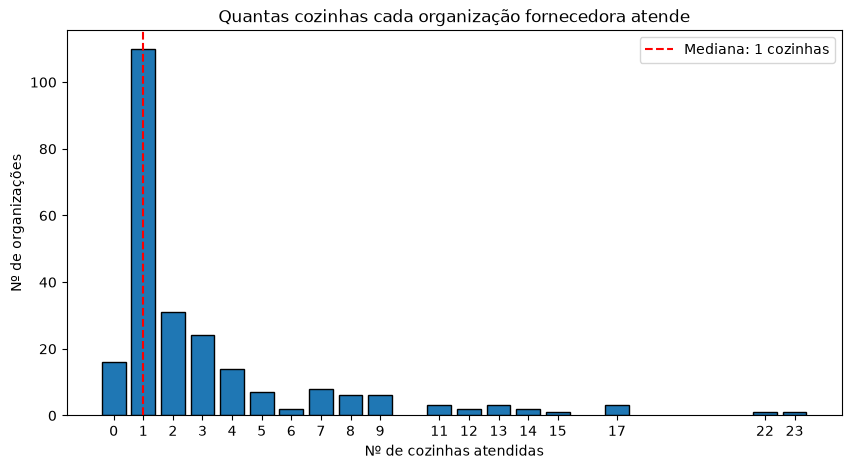

In [58]:
# Conta quantas organizações têm cada nº de cozinhas (ex.: 110 organizações com 1 cozinha)
contagem = por_organizacao["qtd_cozinhas"].value_counts().sort_index()  # sort_index ordena pelo nº de cozinhas, não pela frequência
mediana = por_organizacao["qtd_cozinhas"].median()                      # valor do meio, para marcar no gráfico

plt.figure(figsize=(10, 5))                                  # cria a figura (largura, altura em polegadas)
plt.bar(contagem.index, contagem.values, edgecolor="black")  # uma barra para cada nº de cozinhas; a borda preta separa as barras
# linha vertical tracejada na mediana; o :.0f no f-string mostra o número sem casas decimais
plt.axvline(mediana, color="red", linestyle="--", label=f"Mediana: {mediana:.0f} cozinhas")

plt.title("Quantas cozinhas cada organização fornecedora atende")  # título
plt.xlabel("Nº de cozinhas atendidas")                               # eixo x
plt.ylabel("Nº de organizações")                                     # eixo y
plt.xticks(contagem.index)  # no eixo x, só os valores que existem nos dados (por isso 10, 16 e 18 a 21 não aparecem)
plt.legend()                # mostra a legenda (o texto da linha da mediana)
plt.show()                  # desenha o gráfico

**O que o gráfico mostra:**

- A barra do 1 é de longe a mais alta: **110 das 240 organizações (46%) atendem uma única cozinha.**
- Depois do 1 as barras caem rápido (31 organizações com duas cozinhas, 24 com três…) e, na direita, sobra uma "cauda longa" com poucas organizações atendendo 10, 15, 20 cozinhas.
- A barra do 0 são as 16 organizações sem cozinha cadastrada.

Esse formato, muita gente com pouco e pouca gente com muito, é bem comum nesse tipo de dado. E é exatamente o que a diferença entre média e mediana já tinha sugerido.

### 8.1 O mesmo dado num histograma (e por que ele engana um pouco)

O histograma (`plot(kind="hist")`) é o jeito "automático" de olhar uma distribuição: ele divide o eixo x em faixas (`bins`) e conta quantos valores caem em cada uma.

O problema é que, com `bins=20` e valores indo de 0 a 23, cada faixa fica com 23 ÷ 20 = 1,15 de largura. Aí o 0 e o 1 caem na mesma faixa e a primeira barra mostra 126 (16 + 110). O mesmo acontece com o 7 e o 8 (8 + 6 = 14). O formato geral continua parecido, mas os detalhes se perdem. Para contagens, o gráfico de barras de cima é a melhor escolha. O histograma fica aqui só para comparar.

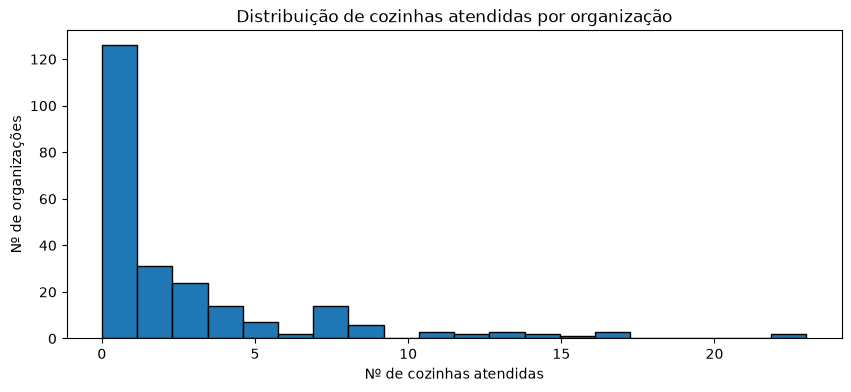

In [59]:
# Histograma: divide o eixo x em 20 faixas de mesmo tamanho e conta quantas organizações caem em cada uma
por_organizacao["qtd_cozinhas"].plot(kind="hist", bins=20, edgecolor="black", figsize=(10, 4))
plt.title("Distribuição de cozinhas atendidas por organização")  # título
plt.xlabel("Nº de cozinhas atendidas")                             # eixo x
plt.ylabel("Nº de organizações")                                   # eixo y
plt.show()                                                         # desenha

# Dica: com bins=range(0, 25) cada número inteiro ganha a sua própria faixa,
# e o resultado fica praticamente igual ao gráfico de barras de cima

## 9. Gráfico 2: as 15 organizações que mais atendem

**Pergunta do gráfico:** quem são as organizações da "cauda longa" do gráfico anterior?

**Por que barras horizontais?** Os nomes das organizações são compridos. Em barras verticais eles ficariam espremidos ou tortos embaixo do gráfico. Na horizontal, cada nome ganha uma linha inteira e dá para ler.

**Por que ordenar de novo?** O `por_organizacao` já está do maior para o menor, mas o `barh` desenha a primeira linha da tabela **embaixo**. Ordenando do menor para o maior, a maior barra vai para o topo, que é onde a gente começa a ler.

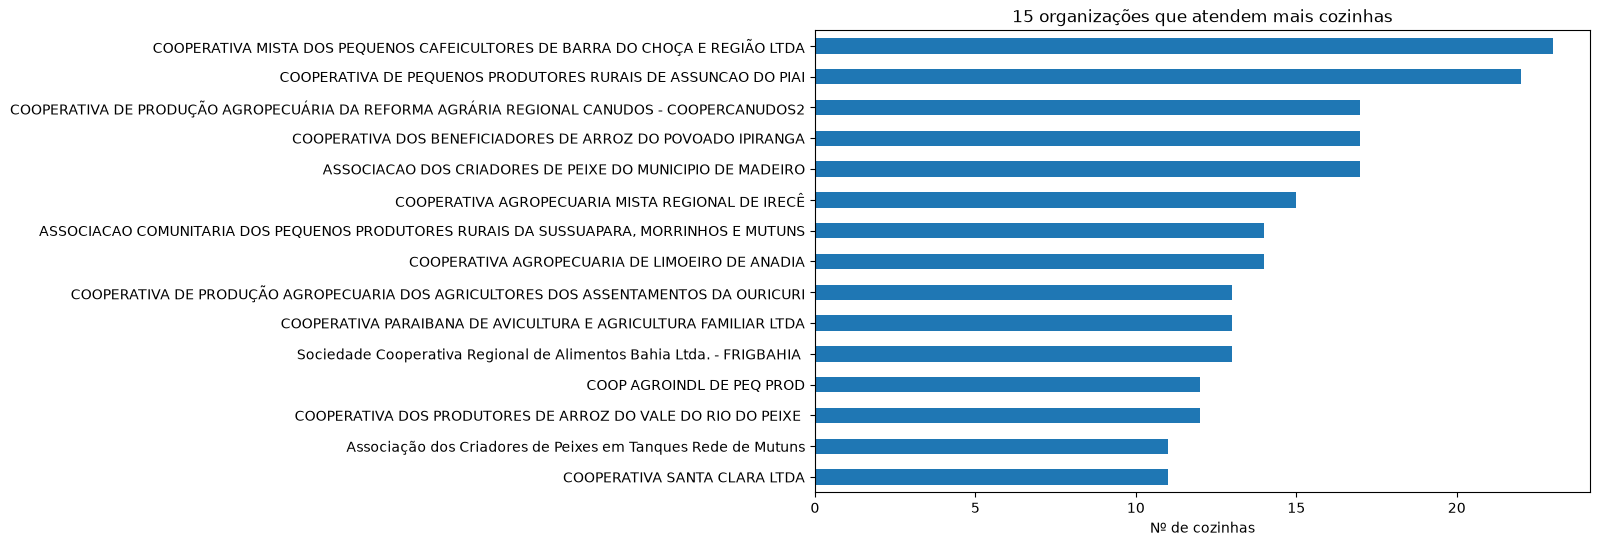

In [60]:
top = por_organizacao.head(15).sort_values("qtd_cozinhas")  # as 15 maiores, em ordem crescente (a maior fica no topo do gráfico)
top.plot(kind="barh", x="organizacao", y="qtd_cozinhas", legend=False, figsize=(10, 6))  # barh = barras horizontais; nomes no eixo vertical
plt.title("15 organizações que atendem mais cozinhas")  # título
plt.xlabel("Nº de cozinhas")                            # eixo x
plt.ylabel("")                                          # tira o rótulo do eixo y (os nomes já se explicam)
plt.show()                                              # desenha

**O que o gráfico mostra:**

- Duas organizações se destacam bem: uma cooperativa de cafeicultores de Barra do Choça (BA), com 23 cozinhas, e uma de pequenos produtores rurais de Assunção do Piauí (PI), com 22.
- Daí para baixo os valores vão de 17 a 11, sem nenhum salto grande.
- Um detalhe: três organizações empatam com 11 cozinhas, mas só cabem duas no top 15. Quando há empate bem no corte, quem entra depende só da ordem das linhas na tabela.
- Essas 15 são a exceção (lembrando que a mediana é 1). Para ter uma ideia da concentração: as 24 maiores organizações, 10% do total, respondem por cerca de 41% de todas as ligações entre organização e cozinha.

Atenção: somar a coluna `qtd_cozinhas` **não** dá o número total de cozinhas, porque uma mesma cozinha pode ser atendida por várias organizações. Por isso falei em "ligações" e não em cozinhas.

## 10. Gráfico 3: comparando os estados

**Pergunta do gráfico:** o padrão "a maioria atende uma cozinha" vale para todos os estados, ou tem estado onde as organizações atendem muito mais?

Primeiro, a mesma contagem da seção 7, só que agrupando por **estado + CNPJ**. Como nenhum CNPJ aparece em mais de uma UF nesses dados, os números são os mesmos de antes; a diferença é que agora cada organização vem com o seu estado.

In [61]:
por_org_estado = (
    juntos.groupby(["UF ORGANIZAÇÃO", "CNPJ"])  # agrupa por estado e, dentro dele, por organização
    .agg(
        organizacao=("ORGANIZAÇÃO FORNECEDORA", "first"),                # nome da organização
        qtd_cozinhas=("Código da Cozinha", "nunique"),                    # nº de cozinhas diferentes
        qtd_sem_cozinha=("Código da Cozinha", lambda x: x.isna().sum()),  # nº de projetos sem cozinha
    )
    .sort_values(["UF ORGANIZAÇÃO", "qtd_cozinhas"], ascending=[True, False])  # estados em ordem alfabética; dentro de cada um, da maior para a menor
)
por_org_estado.head()  # primeiras linhas (AC e AL)

organizacao  \
UF ORGANIZAÇÃO CNPJ                                                                    
AC             09.197.432/0001-09  COOPERATIVA DE PRODUTORES AGROFLORESTAIS E AGR...   
               18.020.228/0001-09  Cooperativa dos Produtores, Extrativistas de A...   
AL             07.716.270/0001-42  COOPERATIVA DOS BENEFICIADORES DE ARROZ DO POV...   
               18.126.811/0001-07  COOPERATIVA DE PRODUÇÃO AGROPECUÁRIA DA REFORM...   
               44.903.463/0001-39     COOPERATIVA AGROPECUARIA DE LIMOEIRO DE ANADIA   

                                   qtd_cozinhas  qtd_sem_cozinha  
UF ORGANIZAÇÃO CNPJ                                               
AC             09.197.432/0001-09             1                0  
               18.020.228/0001-09             1                0  
AL             07.716.270/0001-42            17                0  
               18.126.811/0001-07            17                0  
               44.903.463/0001-39            14                0

**Por que um boxplot?** Ele serve para comparar a **distribuição** de vários grupos lado a lado. Um gráfico de barras para cada estado daria 27 gráficos, e um gráfico só com a média de cada estado esconderia justamente a assimetria que a gente viu. O boxplot resume cada estado numa caixinha:

- **linha dentro da caixa**: a mediana;
- **caixa**: onde estão os 50% do meio (do 1º ao 3º quartil);
- **"bigodes"**: até onde vão os valores considerados normais (por padrão, até 1,5 vez a altura da caixa);
- **bolinhas**: valores fora da curva (*outliers*), muito acima ou muito abaixo do resto do estado.

Um detalhe do código: o `boxplot(..., by=...)` do pandas cria sozinho um título "Boxplot grouped by…" no topo da figura. O `plt.suptitle("")` apaga esse título extra e deixa só o nosso.

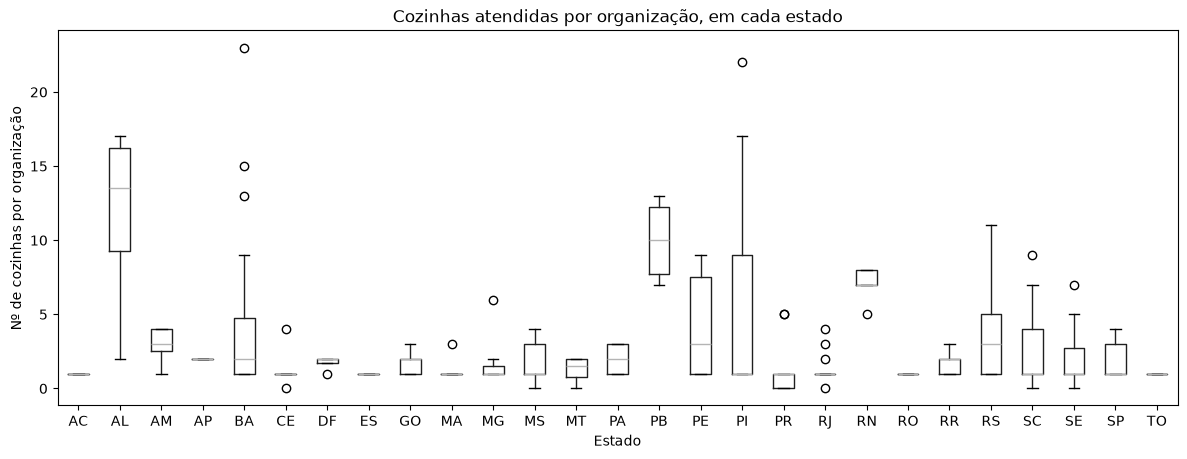

In [62]:
# reset_index devolve UF e CNPJ (que o groupby transformou em índice) para colunas normais,
# porque o boxplot precisa da UF como coluna para separar os grupos
por_org_estado.reset_index().boxplot(
    column="qtd_cozinhas",  # o valor que vira caixinha
    by="UF ORGANIZAÇÃO",    # uma caixinha por estado
    figsize=(14, 5),        # figura bem larga, porque são 27 estados
    grid=False              # sem linhas de grade no fundo
)
plt.title("Cozinhas atendidas por organização, em cada estado")  # o nosso título
plt.suptitle("")                                                  # apaga o título automático "Boxplot grouped by..."
plt.xlabel("Estado")                                              # eixo x
plt.ylabel("Nº de cozinhas por organização")                      # eixo y
plt.show()                                                        # desenha

**O que o gráfico mostra:**

- Na maior parte dos estados a caixinha fica lá embaixo, entre 1 e 3. É o mesmo padrão do país como um todo.
- **AL** (mediana 13,5), **PB** (10) e **RN** (7) fogem da regra: lá as organizações tendem a atender muitas cozinhas cada uma.
- **BA** e **PI** têm mediana baixa (2 e 1), mas valores bem espalhados e bolinhas lá no alto. Essas bolinhas são as duas campeãs do gráfico anterior (23 e 22).
- Em estados como AC, ES, RO e TO a caixa vira um tracinho: todas as organizações de lá atendem exatamente 1 cozinha.

**Cuidado ao comparar:** alguns estados têm pouquíssimas organizações (AC, ES e RO têm só 2; PB tem 4). Um boxplot feito com 2 ou 4 pontos diz muito pouco, e a mediana de 13,5 em AL, por exemplo, vem de só 6 organizações. E lembrando: o estado aqui é o **da organização**, não o da cozinha.

## 11. Exportando o resultado

Salva a tabela final (uma linha por organização) num arquivo Excel, para consultar fora do Python ou compartilhar. O arquivo vai para a mesma pasta do notebook, e o CNPJ (que é o índice da tabela) vira a primeira coluna da planilha.

In [63]:
# Salva a tabela por organização em Excel (precisa do openpyxl, instalado lá no começo)
por_organizacao.to_excel("cozinhas_por_organizacao.xlsx")